Experiment2

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10214 entries, 0 to 10213
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10214 non-null  int64  
 1   Order ID        10214 non-null  object 
 2   Order Date      10214 non-null  object 
 3   Ship Date       10214 non-null  object 
 4   Ship Mode       10214 non-null  object 
 5   Customer ID     10214 non-null  object 
 6   Customer Name   10214 non-null  object 
 7   Segment         10214 non-null  object 
 8   Country/Region  10214 non-null  object 
 9   City            10214 non-null  object 
 10  State/Province  10214 non-null  object 
 11  Postal Code     10184 non-null  object 
 12  Region          10214 non-null  object 
 13  Product ID      10214 non-null  object 
 14  Category        10214 non-null  object 
 15  Sub-Category    10214 non-null  object 
 16  Product Name    10214 non-null  object 
 17  Sales           10194 non-null 

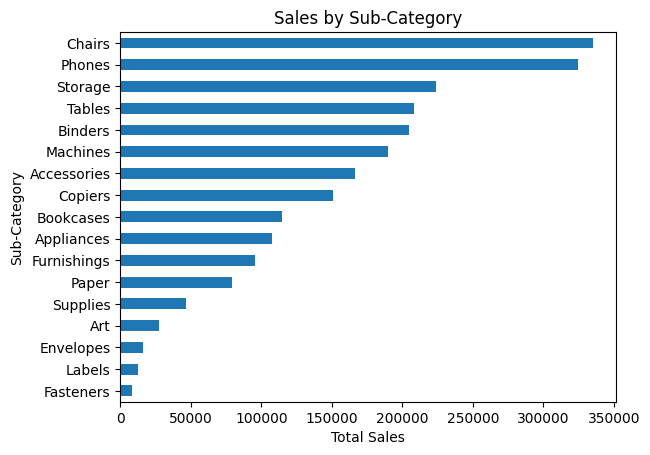

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 2(a) Load & Inspect
df = pd.read_csv('/content/superstore_unclean.csv')
print(df.info(), df.shape)

# 2(b) Clean Data
df = df.drop_duplicates()
df['Sales'] = pd.to_numeric(df['Sales'].str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
df['Order Date'] = pd.to_datetime(df['Order Date'], format='mixed', errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='mixed', errors='coerce')
df['Ship Mode'] = df['Ship Mode'].str.strip().str.title()
df['Region'] = df['Region'].str.strip().str.title()
df = df.dropna(subset=['Sales', 'Order Date'])
df = df[(df['Quantity'] > 0) & (df['Ship Date'] >= df['Order Date'])]

# 2(c) Summarize & 2(d) Visualize
print(df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False).head(3))
df.groupby('Sub-Category')['Sales'].sum().sort_values().plot(kind='barh', title='Sales by Sub-Category')
plt.xlabel('Total Sales')
plt.show()

Experiemnt 3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 4.2 MB/s eta 0:00:00
VADER:
 vader_sentiment
positive    7615
negative    4464
neutral     2561
Name: count, dtype: int64 
Human:
 airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


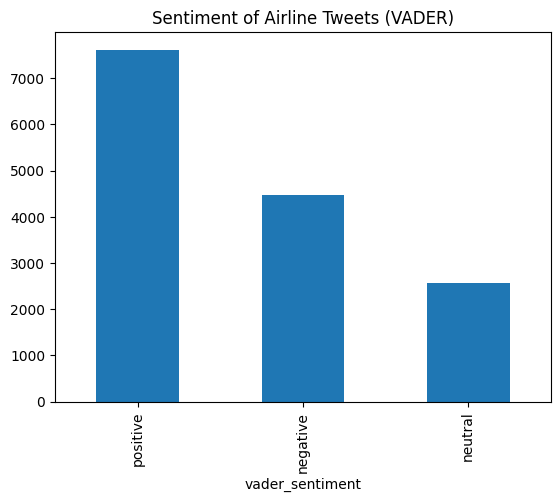

                                                 text airline_sentiment  \
1   @VirginAmerica plus you've added commercials t...          positive   
7   @VirginAmerica Really missed a prime opportuni...           neutral   
10  @VirginAmerica did you know that suicide is th...           neutral   
16  @VirginAmerica So excited for my first cross c...          positive   
17  @VirginAmerica  I flew from NYC to SFO last we...          negative   

   vader_sentiment  
1          neutral  
7         positive  
10        negative  
16        negative  
17        positive  


In [ ]:
!pip install vaderSentiment
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

df = pd.read_csv('/content/airline_tweets.csv')
analyzer = SentimentIntensityAnalyzer()

def get_sentiment(text):
    score = analyzer.polarity_scores(str(text))['compound']
    return 'positive' if score >= 0.05 else ('negative' if score <= -0.05 else 'neutral')

df['vader_sentiment'] = df['text'].apply(get_sentiment)
print("VADER:\n", df['vader_sentiment'].value_counts(), "\nHuman:\n", df['airline_sentiment'].value_counts())

df['vader_sentiment'].value_counts().plot(kind='bar', title='Sentiment of Airline Tweets (VADER)')
plt.show()

# View mismatches (Sarcasm hunt)
print(df[df['vader_sentiment'] != df['airline_sentiment']][['text', 'airline_sentiment', 'vader_sentiment']].head())

Experiemnt 4

         Recency  Frequency  Monetary  Customers
Segment                                         
0           98.7        4.7    1615.7        340
1          546.1        3.8    1585.0        103
2          113.9        8.6    9449.9         67
3           70.6        8.7    3336.1        294


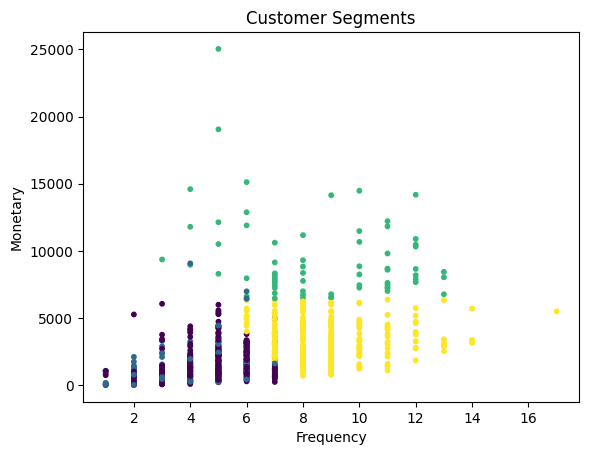

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_csv('/content/superstore_orders.csv')
df['Order Date'] = pd.to_datetime(df['Order Date'])
ref_date = df['Order Date'].max() + pd.Timedelta(days=1)

rfm = df.groupby('Customer ID').agg(
    Recency=('Order Date', lambda x: (ref_date - x.max()).days),
    Frequency=('Order ID', 'nunique'),
    Monetary=('Sales', 'sum')
).reset_index()

scaled = StandardScaler().fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])
rfm['Segment'] = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(scaled)

summary = rfm.groupby('Segment')[['Recency', 'Frequency', 'Monetary']].mean()
summary['Customers'] = rfm.groupby('Segment').size()
print(summary.round(1))

plt.scatter(rfm['Frequency'], rfm['Monetary'], c=rfm['Segment'], cmap='viridis', s=10)
plt.xlabel('Frequency'); plt.ylabel('Monetary'); plt.title('Customer Segments')
plt.show()

Experiment 5

               antecedents            consequents   support  confidence  \
239              (sausage)   (whole milk, yogurt)  0.001470    0.024363   
234   (whole milk, yogurt)              (sausage)  0.001470    0.131737   
235  (whole milk, sausage)               (yogurt)  0.001470    0.164179   
238               (yogurt)  (whole milk, sausage)  0.001470    0.017121   
86   (specialty chocolate)         (citrus fruit)  0.001403    0.087866   
87          (citrus fruit)  (specialty chocolate)  0.001403    0.026415   
236      (yogurt, sausage)           (whole milk)  0.001470    0.255814   
237           (whole milk)      (yogurt, sausage)  0.001470    0.009310   
122       (tropical fruit)                (flour)  0.001069    0.015779   
123                (flour)       (tropical fruit)  0.001069    0.109589   

         lift  
239  2.182917  
234  2.182917  
235  1.911760  
238  1.911760  
86   1.653762  
87   1.653762  
236  1.619866  
237  1.619866  
122  1.617141  
123  1.617141 

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


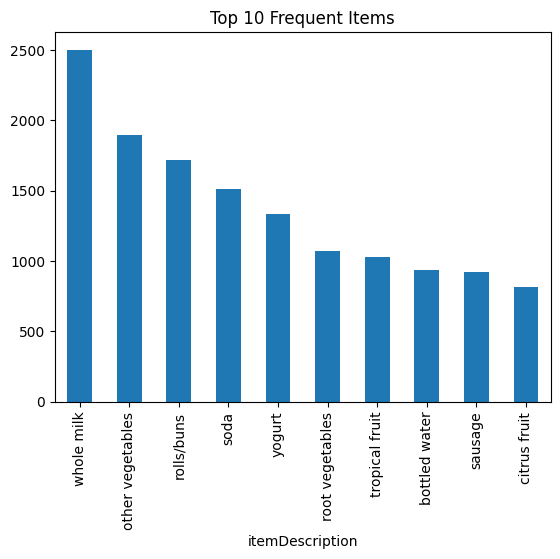

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
!pip install mlxtend
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

df = pd.read_csv('/content/Groceries_dataset.csv')
df['basket'] = df['Member_number'].astype(str) + '_' + df['Date'].astype(str)
transactions = df.groupby('basket')['itemDescription'].apply(list).tolist()

te = TransactionEncoder()
basket_table = pd.DataFrame(te.fit_transform(transactions), columns=te.columns_)

freq_items = apriori(basket_table, min_support=0.001, use_colnames=True)
rules = association_rules(freq_items, metric='lift', min_threshold=1).sort_values('lift', ascending=False)
print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))

df['itemDescription'].value_counts().head(10).plot(kind='bar', title='Top 10 Frequent Items')
plt.show()

Experiment 6

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

R2: 0.489 | MAE: 61.76 | RMSE: 214.05


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


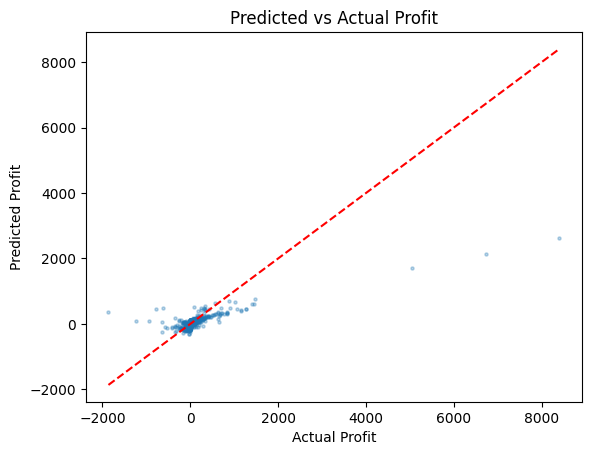

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv('/content/superstore_orders.csv')
X = pd.get_dummies(df[['Sales', 'Quantity', 'Discount', 'Category', 'Sub-Category', 'Region']], drop_first=True)
y = df['Profit']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
preds = model.predict(X_test)

print(f"R2: {r2_score(y_test, preds):.3f} | MAE: {mean_absolute_error(y_test, preds):.2f} | RMSE: {np.sqrt(mean_squared_error(y_test, preds)):.2f}")

plt.scatter(y_test, preds, s=5, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Profit'); plt.ylabel('Predicted Profit'); plt.title('Predicted vs Actual Profit')
plt.show()

Experiment 7

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

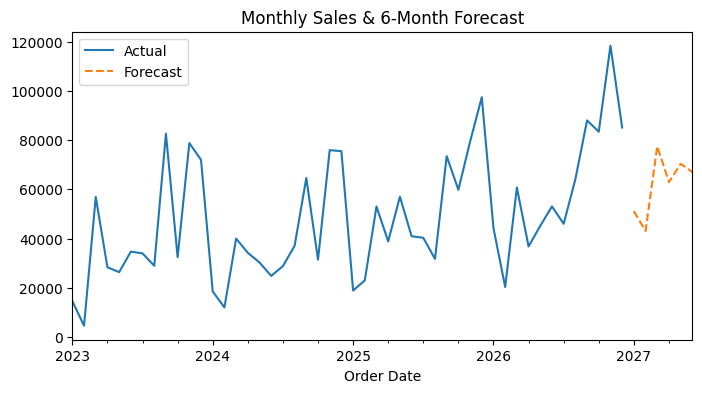

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Holdout MAPE: 16.1%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

df = pd.read_csv('/content/superstore_orders.csv')
df['Order Date'] = pd.to_datetime(df['Order Date'])
monthly = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()
monthly.index = monthly.index.to_timestamp()

# Fit & Forecast 6 months
model = ExponentialSmoothing(monthly, trend='add', seasonal='add', seasonal_periods=12).fit()
forecast = model.forecast(6)

monthly.plot(label='Actual', figsize=(8, 4))
forecast.plot(label='Forecast', style='--', title='Monthly Sales & 6-Month Forecast')
plt.legend(); plt.show()

# Holdout evaluation (last 6 months)
train, test = monthly.iloc[:-6], monthly.iloc[-6:]
pred = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=12).fit().forecast(6)
mape = (abs(test - pred) / test).mean() * 100
print(f"Holdout MAPE: {mape:.1f}%")

Experiemnt 8

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Flagged 204 out of 10194 orders.
               Sales  Quantity  Discount      Profit
anomaly                                             
-1       2883.152927  6.607843  0.275196  320.804777
 1        174.011127  3.734334  0.152938   22.707972


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

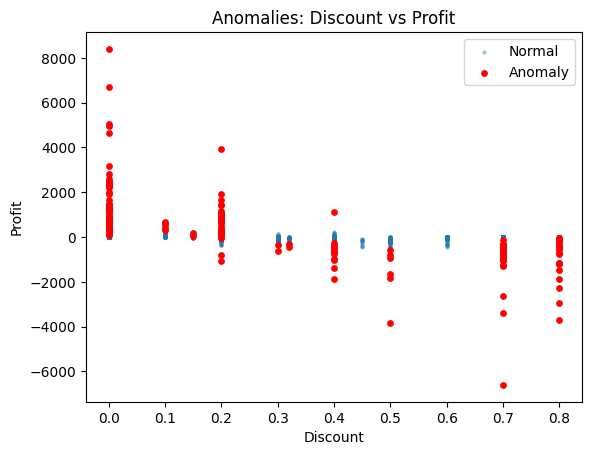

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

df = pd.read_csv('/content/superstore_orders.csv')
features = ['Sales', 'Quantity', 'Discount', 'Profit']

model = IsolationForest(contamination=0.02, random_state=42)
df['anomaly'] = model.fit_predict(df[features])

anomalies = df[df['anomaly'] == -1]
normal = df[df['anomaly'] == 1]
print(f"Flagged {len(anomalies)} out of {len(df)} orders.")
print(df.groupby('anomaly')[features].mean())

plt.scatter(normal['Discount'], normal['Profit'], s=5, alpha=0.3, label='Normal')
plt.scatter(anomalies['Discount'], anomalies['Profit'], s=15, color='red', label='Anomaly')
plt.xlabel('Discount'); plt.ylabel('Profit'); plt.title('Anomalies: Discount vs Profit')
plt.legend(); plt.show()